# 05b — Seven-field targets, strict parsing, and training feasibility

**Phase 4 · Dataset and resource workshop · Train/validation only**

Notebook A showed that a pretrained document reader does not automatically return
our seven-field schema. Here we turn the task into supervised examples and make
every structural failure explicit before fitting a task model.

By the end, you should be able to construct an image/sequence pair, explain the
single teacher-forcing shift, distinguish malformed structure from wrong values,
and explain why a successful inference or two-step probe may not establish
reliable training headroom.

Read [the training concepts](../docs/learning/donut-training.md) alongside this
workshop. The [resource report](../docs/experiments/donut-feasibility.md) owns the
named measurements; [the dataset policy](../configs/donut_dataset_v1.json) owns
serialization and preprocessing settings.

## How to run and learn

Use the repository `.venv`, restore MIDV and notebook A's pinned checkpoint,
then **Restart Kernel and Run All**. This notebook actively reconstructs every
permitted observation, tokenizes all targets, exercises the parser, and audits
recorded resource experiments. The complete optimizer probes ran in **separate
fresh processes** to isolate CUDA allocations; their real outputs are loaded
below. They are not simulated memory estimates or fabricated notebook results.

```bash
.venv/bin/python -m experiments.execute_phase4_notebook 05b_donut_dataset
```

Before each section, predict what the next check should show. Use a scratch copy
for exercises and retain this executed record. Do not run GPU resource probes
while another training job is resident: that changes the memory comparison.

In [1]:
from pathlib import Path
import inspect, json, os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer
from IPython.display import display

here=Path.cwd().resolve()
ROOT=next(p for p in [here,*here.parents] if (p/'PROJECT.md').is_file())
from experiments.donut_workshop import (load_observations, read_json, write_json, new_run,
                                      setup, sha, target_ids, teacher_forcing)
from experiments.donut_protocol import (schema_tokens, serialize_fields, parse_sequence,
                                      TASK_TOKEN, EOS_TOKEN)
from kyc_router.normalization import normalize_document_values
from kyc_router.evaluation import score_document
from kyc_router.schema import REQUIRED_FIELDS
setup()
policy=read_json(ROOT/'configs/donut_dataset_v1.json')
RUN=new_run('phase4_dataset')
print('Dataset evidence:',RUN.relative_to(ROOT))

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset evidence: outputs/phase4_dataset/20261015T122852277251Z


## 1. Audit identities before using images

Training and validation have different jobs. Training changes weights; validation
chooses among declared candidates. Both may be examined during development, but
the 15 test identities remain sealed. A template and photograph share an
identity, so they must never land on opposite sides of a split.

The adapter rejects a forbidden split before opening an image. Shared VIA files
contain records for other identities, but the adapter selects only allowed
filenames; it never uses test field values. Photo annotations supply geometry,
not a second complete transcription table. References for both views come from
the identity-matched template, as in Phase 3.

**Predict:** how many observations should 70 training and 15 validation identities
produce when each has one template and one photograph? Are these 170 independent identities?

In [2]:
try:
    load_observations(splits=('test',))
except PermissionError as error:
    print('Expected sealed-test rejection:',error)
else:
    raise AssertionError('Test access was not refused.')
observations=load_observations()
metadata=pd.DataFrame([{k:o[k] for k in ('identity_key','split','source','pixel_sha256')}
                       for o in observations])
assert len(observations)==170
assert not metadata.duplicated(['identity_key','source']).any()
train_ids=set(metadata.loc[metadata.split.eq('train'),'identity_key'])
val_ids=set(metadata.loc[metadata.split.eq('validation'),'identity_key'])
assert len(train_ids)==70 and len(val_ids)==15 and train_ids.isdisjoint(val_ids)
assert metadata.groupby('identity_key').source.nunique().eq(2).all()
display(metadata.groupby(['split','source']).agg(observations=('identity_key','size'),identities=('identity_key','nunique')))

Expected sealed-test rejection: Test remains sealed throughout Phase 4.


observations  identities
split      source                            
train      photo               70          70
           template            70          70
validation photo               15          15
           template            15          15

## 2. Write down the output grammar

All seven normalized fields appear in a fixed training order. A task token starts
the sequence, a matching opening/closing tag bounds each value, and EOS ends the
document. This is the model's training target, not a post-hoc dictionary assembled
from a lookup table. Literal `&`, `<`, and `>` in values need escaping so they
cannot impersonate delimiters. Unicode and meaningful punctuation remain intact.

Read the actual serializer below, then manually locate the start/end of two
values in the example. The same function creates all training targets. Original
annotation strings remain available separately; harmless normalization never
replaces raw evidence of a generated error.

In [3]:
example=next(o for o in observations if o['split']=='train')
print(inspect.getsource(serialize_fields))
sequence=serialize_fields(example['truth'])
print('Training identity:',example['identity_key'])
print(sequence)
display(pd.DataFrame({'raw annotation':example['truth_raw'],'normalized target':example['truth']}))
assert parse_sequence(sequence)['fields']==example['truth']

def serialize_fields(fields):
    """Serialize already-normalized values; preserve Unicode and punctuation."""
    if set(fields) != set(REQUIRED_FIELDS):
        raise ValueError("Targets require exactly the seven v1 fields.")
    if any(not isinstance(fields[f], str) or not fields[f] for f in REQUIRED_FIELDS):
        raise ValueError("Training targets require nonempty strings.")
    return TASK_TOKEN + "".join(
        f"<s_{field}>{html.escape(fields[field], quote=False)}</s_{field}>"
        for field in REQUIRED_FIELDS
    ) + EOS_TOKEN

Training identity: alb_id/02
<s_alb_id><s_document_number>391378355</s_document_number><s_surname>ahmeti</s_surname><s_given_names>agim</s_given_names><s_date_of_birth>1973-10-15</s_date_of_birth><s_expiry_date>2025-08-07</s_expiry_date><s_nationality>shqiptare/albanian</s_nationality><s_sex>M</s_sex></s>


,raw annotation,normalized target
document_number,391378355,391378355
surname,Ahmeti,ahmeti
given_names,Agim,agim
date_of_birth,15-10-1973,1973-10-15
expiry_date,07-08-2025,2025-08-07
nationality,Shqiptare/Albanian,shqiptare/albanian
sex,M,M


### 2.1 Token IDs are the model's actual labels

Register the 15 schema symbols with an isolated tokenizer. Notebook A already
showed why these symbols need resized decoder embeddings. No neural weights are
loaded in this notebook kernel; the resource workers perform model training
checks in fresh processes.

SentencePiece decoding can introduce leading spaces inside values. Verify the
tokenized target still parses and matches after the **same shared normalization**
that scores both pipelines. Do not silently change the parser or strip arbitrary
generated characters to make a round trip appear correct.

**Predict:** will target character count equal token count? What would silently
truncating a target teach the model about its last field and EOS?

In [4]:
tokenizer=AutoTokenizer.from_pretrained(ROOT/policy['parent_checkpoint'],local_files_only=True)
before=len(tokenizer)
added=tokenizer.add_special_tokens({'additional_special_tokens':schema_tokens()})
assert added==15 and len(tokenizer)==before+15
class TargetProcessor:
    pass
target_processor=TargetProcessor()
target_processor.tokenizer=tokenizer
length_rows=[]
for obs in observations:
    ids=target_ids(target_processor,obs['truth'],policy['max_target_tokens'])
    decoded=tokenizer.decode(ids,skip_special_tokens=False,clean_up_tokenization_spaces=False)
    assert normalize_document_values(parse_sequence(decoded)['fields'])==obs['truth']
    length_rows.append({'identity_key':obs['identity_key'],'split':obs['split'],'source':obs['source'],
                        'target_tokens':len(ids),'target_characters':len(serialize_fields(obs['truth']))})
lengths=pd.DataFrame(length_rows)
display(lengths.groupby('split')[['target_tokens','target_characters']].agg(['min','median','max']))
print('Vocabulary:',before,'→',len(tokenizer))
print('Target decoded through the tokenizer:',repr(tokenizer.decode(target_ids(target_processor,example['truth']),skip_special_tokens=False)))

target_tokens            target_characters            
                     min median max               min median  max
split                                                            
train                 37   39.0  43               276  278.0  286
validation            37   39.0  41               276  281.0  284

Vocabulary: 57525 → 57540
Target decoded through the tokenizer: '<s_alb_id><s_document_number> 391378355</s_document_number><s_surname> ahmeti</s_surname><s_given_names> agim</s_given_names><s_date_of_birth> 1973-10-15</s_date_of_birth><s_expiry_date> 2025-08-07</s_expiry_date><s_nationality> shqiptare/albanian</s_nationality><s_sex> M</s_sex></s>'


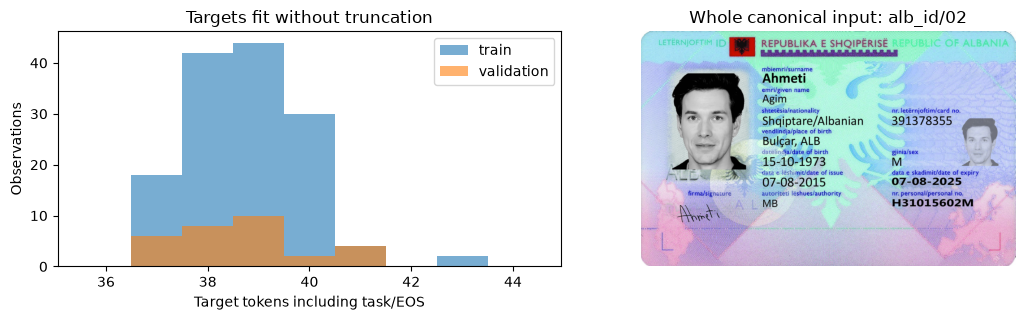

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,3.3))
for split_name,group in lengths.groupby('split'):
    axes[0].hist(group.target_tokens,alpha=.6,label=split_name,bins=np.arange(35.5,45.5))
axes[0].set(xlabel='Target tokens including task/EOS',ylabel='Observations',title='Targets fit without truncation')
axes[0].legend()
axes[1].imshow(example['image'])
axes[1].set_title(f"Whole canonical input: {example['identity_key']}")
axes[1].axis('off')
fig.tight_layout()
fig.savefig(RUN/'targets_and_input.png',bbox_inches='tight')
plt.show()

## 3. Test failure semantics before scoring a model

A strict parser separates three issues:

- Broken grammar, duplicate keys, or an incomplete task/EOS envelope make the
  whole sequence structurally invalid. The shared scorer then sees no fields.
- A well-formed partial mapping retains its other values. Missing required keys
  lose their own Exact Match credit; extra keys remain schema violations.
- An empty value or impossible date may parse, yet fail semantic validation.

The parser accepts field permutations at inference even though targets use a
fixed order. This avoids inventing an order penalty absent from the field-scoring
contract. Inspect the implementation and the adversarial examples below.

**Predict:** should duplicate `sex` values be resolved by taking the last one?
That would silently hide one prediction, so the frozen policy rejects duplicates.

In [6]:
print(inspect.getsource(parse_sequence))
good=serialize_fields(example['truth'])
cases={
    'complete':good,
    'missing sex':good.replace(f"<s_sex>{example['truth']['sex']}</s_sex>",''),
    'extra key':good.replace(EOS_TOKEN,'<s_extra>x</s_extra>'+EOS_TOKEN),
    'duplicate key':good.replace(EOS_TOKEN,'<s_sex>F</s_sex>'+EOS_TOKEN),
    'missing EOS':good[:-len(EOS_TOKEN)],
    'unbalanced tag':good.replace('</s_surname>','</s_sex>'),
    'invalid date':good.replace(example['truth']['date_of_birth'],'1973-02-30'),
    'empty sex':good.replace(f"<s_sex>{example['truth']['sex']}</s_sex>",'<s_sex></s_sex>'),
}
case_rows=[]
for name,value in cases.items():
    parsed=parse_sequence(value)
    fields,doc=score_document(example['truth'],parsed['fields'])
    case_rows.append({'case':name,'structural_failure':doc['structural_failure'],
                      'correct_fields':sum(r['normalized_exact_match'] for r in fields),
                      'schema_valid':doc['schema_is_valid'],'parser_errors':parsed['errors']})
display(pd.DataFrame(case_rows))
assert next(r for r in case_rows if r['case']=='duplicate key')['correct_fields']==0
assert next(r for r in case_rows if r['case']=='missing sex')['correct_fields']==6

def parse_sequence(sequence):
    """Parse the declared envelope and grammar, without guessing or correction.

    Any malformed/duplicate sequence returns fields=None: the shared scorer
    then counts all fields missing. A well-formed partial mapping retains its
    other fields; extra keys remain visible to the scorer as schema violations.
    """
    def failure(reason):
        return {"fields": None, "structural_failure": True, "errors": [reason]}

    if not isinstance(sequence, str):
        return failure("not_a_string")
    if not sequence.startswith(TASK_TOKEN):
        return failure("missing_task_token")
    if not sequence.endswith(EOS_TOKEN):
        return failure("missing_eos")
    body = sequence[len(TASK_TOKEN):-len(EOS_TOKEN)]
    fields, position = {}, 0
    while position < len(body):
        match = FIELD_PATTERN.match(body, position)
        if match is None:
            return failure("malformed_field_sequence")
        name, escaped = match.groups()
        if

,case,structural_failure,correct_fields,schema_valid,parser_errors
0,complete,False,7,True,[]
1,missing sex,False,6,False,[]
2,extra key,False,7,False,[]
3,duplicate key,True,0,False,[duplicate_field]
4,missing EOS,True,0,False,[missing_eos]
5,unbalanced tag,True,0,False,[malformed_field_sequence]
6,invalid date,False,6,True,[]
7,empty sex,False,6,True,[]


## 4. Trace the teacher-forcing alignment

For `[task, field_open, value, field_close, EOS]`, input positions contain all
but the last token and labels contain all but the first. This performs **one
shift**. Our installed mBART causal decoder compares the aligned logits and
labels without shifting again. The first task token is supplied context, while
EOS is a prediction target. Passing references is appropriate for training;
generation at validation/inference gets only the task prefix.

The first table pairs input and label tokens. Then a small padding demonstration
shows where `-100` would mask padded labels if we used variable-length batches.
The actual training policy uses one unpadded example per microbatch, accumulating
four gradients before each main optimizer update.

In [7]:
ids=target_ids(target_processor,example['truth'])
inputs,labels=teacher_forcing(ids,'cpu')
assert inputs.shape==labels.shape and inputs.shape[1]==len(ids)-1
assert inputs[0,0].item()==tokenizer.convert_tokens_to_ids(TASK_TOKEN)
assert labels[0,-1].item()==tokenizer.eos_token_id
display(pd.DataFrame({'position':range(min(16,len(ids)-1)),
                      'decoder input':tokenizer.convert_ids_to_tokens(inputs[0,:16].tolist()),
                      'next-token label':tokenizer.convert_ids_to_tokens(labels[0,:16].tolist())}))
short=labels[0,:-3]
padded=torch.nn.utils.rnn.pad_sequence([labels[0],short],batch_first=True,padding_value=-100)
print('Padding demonstration, last six labels per example:')
display(pd.DataFrame(padded[:,-6:].numpy()))
assert (padded[1,-3:]==-100).all()

,position,decoder input,next-token label
0,0,<s_alb_id>,<s_document_number>
1,1,<s_document_number>,▁39
2,2,▁39,137
3,3,137,83
4,4,83,55
5,5,55,</s_document_number>
6,6,</s_document_number>,<s_surname>
7,7,<s_surname>,▁ah
8,8,▁ah,meti
9,9,meti,</s_surname>


Padding demonstration, last six labels per example:


,0,1,2,3,4,5
0,49889,57537,57538,34837,57539,2
1,49889,57537,57538,-100,-100,-100


## 5. Read actual complete-step resource evidence

Weights and activations are only part of training memory. Gradients and optimizer
state appear during backward/update; AdamW may allocate its moments lazily on the
first update. We measured fresh processes and retained OOMs rather than claiming
feasibility from notebook A's successful forward calls.

The declared sequence tried full checkpointed float32 training and then a frozen
encoder. Follow-ups moved the frozen encoder off GPU during decoder updates,
then used factored-state Adafactor to leave more memory headroom. All decoder
parameters, including the new schema embeddings, remain trainable. This is not
full-model fine-tuning, and the reports keep that limitation explicit.

**Predict:** why can a two-step pass still be followed by OOM? Device memory from
the desktop changes, and different execution stages can have different peaks.
Ten successful Adafactor steps establish measured headroom for this setup, not
a universal guarantee on every machine or concurrent workload.

In [8]:
resource_rows=[]
resource_records=[]
for result_path in sorted((ROOT/'outputs/phase4_feasibility').glob('*/result.json')):
    result=read_json(result_path)
    resource_records.append({'run':str(result_path.parent.relative_to(ROOT)),**result})
    resource_rows.append({'run':result_path.parent.name,'mode':result['mode'],'status':result['status'],
                          'stage':result['stage'],'completed_steps':result['completed_optimizer_steps'],
                          'peak_allocated_mib':result['memory']['cuda_peak_allocated_mib'],
                          'error':result.get('error_type','')})
display(pd.DataFrame(resource_rows))
selected=next(r for r in resource_records if r['mode']=='frozen_features_adafactor' and r['status']=='passed')
assert selected['completed_optimizer_steps']==10
display(pd.DataFrame(selected['steps']))
print('Reproduce in a fresh process, after freeing other research GPU models:')
print('.venv/bin/python -m experiments.donut_feasibility --mode frozen_features_adafactor')

,run,mode,status,stage,completed_steps,peak_allocated_mib,error
0,20261015T121455832353Z,full_checkpointed,failed,load,0,0.000000,AssertionError
1,20261015T121507255226Z,full_checkpointed,failed,step_1_backward,0,2573.671875,OutOfMemoryError
2,20261015T121606315164Z,frozen_encoder,failed,step_1_optimizer,0,2495.598145,OutOfMemoryError
3,20261015T121708609758Z,frozen_features,passed,complete,2,2426.126465,
4,20261015T122314734067Z,frozen_features_adafactor,passed,complete,10,1453.044434,


,step,loss,seconds,gradient_norm_before_clip,rss_mib,cuda_allocated_mib,cuda_reserved_mib,cuda_peak_allocated_mib,cuda_peak_reserved_mib
0,1,15.390189,0.226273,152.560913,2412.746094,1003.429688,1500.0,1452.402344,1500.0
1,2,11.943381,0.134614,114.839096,2412.914062,1003.289551,1502.0,1453.044434,1502.0
2,3,9.974496,0.138106,123.694702,2412.929688,1003.289551,1502.0,1453.044434,1502.0
3,4,9.880441,0.134958,62.162189,2412.953125,1003.289551,1502.0,1453.044434,1502.0
4,5,8.894920,0.135386,69.843719,2412.960938,1003.289551,1502.0,1453.044434,1502.0
5,6,7.288599,0.134718,24.164133,2412.964844,1003.289551,1502.0,1453.044434,1502.0
6,7,6.475220,0.134441,79.801758,2412.968750,1003.289551,1502.0,1453.044434,1502.0
7,8,5.520084,0.134898,43.288940,2412.968750,1003.289551,1502.0,1453.044434,1502.0
8,9,8.674732,0.134681,99.432014,2412.968750,1003.289551,1502.0,1453.044434,1502.0
9,10,5.302830,0.135083,30.226669,2412.972656,1003.289551,1502.0,1453.044434,1502.0


Reproduce in a fresh process, after freeing other research GPU models:
.venv/bin/python -m experiments.donut_feasibility --mode frozen_features_adafactor


### 5.1 Why the chosen cache does not change the inference input

Because encoder weights and preprocessing are fixed, the encoded training image
can be computed once and reused. Cache provenance binds features to exact
pixels, encoder state, processor policy, and identity/split metadata. It contains
no target text. The decoder receives features during fitting; a new inference
request still runs the whole image encoder. The comparison notebook excludes
training feature caches from latency measurements.

Adafactor stores factored row/column statistics for large matrices instead of
two full AdamW moment tensors. We explicitly disable its automatic relative
learning-rate/parameter scaling and use a declared warm-up/decay schedule.
Its own update clipping is used without additional global gradient clipping.
Inspect the selected training policy before running a long job.

**Provenance lesson:** an early generation smoke used a positional cache index
without binding the feature to the requested image. Its matching outputs were
invalid as cache-parity evidence and are marked as such in the report. Main
training checked every metadata row; the final verification used correctly keyed
records. Bind identity, source, split, pixel hash, and encoder/processor policy;
then compare features as well as outputs. Repeated model output cannot prove
that two inputs were identical.

In [9]:
training=read_json(ROOT/'configs/donut_finetuning_v2.json')
assert training['test_evaluated'] is False
assert training['training']['optimizer']=='Adafactor'
display(pd.Series(training['training'],name='frozen main training settings').to_frame())
write_json(RUN/'dataset_audit.json',{
    'identity_counts':{'train':len(train_ids),'validation':len(val_ids)},
    'observations':len(observations),'all_round_trips_passed':True,
    'target_token_min':int(lengths.target_tokens.min()),'target_token_max':int(lengths.target_tokens.max()),
    'vocabulary_before':before,'vocabulary_after':len(tokenizer),
    'test_loaded':False,'dataset_policy_sha256':sha(ROOT/'configs/donut_dataset_v1.json'),
    'metadata':metadata.to_dict(orient='records'),'parser_cases':case_rows,
    'selected_resource_run':selected['run'],
})
lengths.to_csv(RUN/'target_lengths.csv',index=False)
write_json(RUN/'resource_records.json',resource_records)
print('Saved dataset/parser/resource audit:',RUN.relative_to(ROOT))

,frozen main training settings
optimizer,Adafactor
learning_rate,0.00005
weight_decay,0.01
microbatch_size,1
gradient_accumulation,4
effective_batch_size,4
gradient_clip_norm,None
max_epochs,24
learning_rate_schedule,linear warmup then linear decay
warmup_optimizer_steps,35


Saved dataset/parser/resource audit: outputs/phase4_dataset/20261015T122852277251Z


## Checkpoint and exercises

Explain, without reading the code:

1. Why are 170 observations only 85 identities? Why is the photo's reference
   taken from its paired template rather than invented from visible model output?
2. How do escaping, delimiters, and a missing EOS affect parsing? Why do an
   impossible date and a duplicate field belong to different failure categories?
3. Where is the only teacher-forcing shift? Which token is supplied but not
   predicted, and why would padding labels be `-100` in a larger batch?
4. Why is a feature cache legitimate with a frozen deterministic encoder and
   invalid once that encoder changes? Why must inference timing encode new images?
5. What did each memory failure teach that the preceding successful step did not?

**Exercise A:** in a scratch dictionary, put a diacritic, apostrophe, ampersand,
and literal delimiter-looking string in a name. Show both string and token-ID
round trips, then verify normalized equality without removing meaningful text.

**Exercise B:** remove a middle field, duplicate it, and reorder all fields.
Predict the seven-field score before invoking the shared scorer. Keep every
observation in the denominator, even when the sequence is wholly unparseable.

**Exercise C:** derive the rough weights/gradients/AdamW-state memory estimate
from the parameter count in notebook A. Compare it with measured allocated and
reserved peaks; explain why the estimate is not a measurement.

Next: [05c — fine-tuning](05c_donut_finetuning.ipynb), with a separate tiny
memorization diagnostic, a reset to the pretrained parent, and bounded main
training/validation selection. The [phase plan](../docs/workshops/phase-4.md)
tracks the remaining deliverables. No test identities are needed for this work.